In [1]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import ResNet18_Weights

### Settings

In [2]:
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 12
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
#added for early stopping
EARLY_STOPPING_PATIENCE = 3

train_dir = r"Image Training Data/Image Training Data"
test_dir  = r"Image Test Data/Image Test Data"


test_csv_path = r"image_classification_test_labels.csv"

### Set Seed For Reproducibility

In [3]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

### Set Up Stuff for Torch311

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


### Set up Datasets

In [5]:
class_names = sorted([
    d for d in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, d))
])

class_to_idx = {cls: idx for idx, cls in enumerate(class_names)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}

print("Classes:", class_names)
print("Num classes:", len(class_names))

Classes: ['Adult', 'Airplane', 'Alpaca', 'Bird', 'Bus', 'Car', 'Cat', 'Child', 'Dog', 'Elephant', 'Flower', 'Giraffe', 'Horse', 'Monkey', 'Panda', 'Reptile', 'Train', 'Vessel', 'Zebra']
Num classes: 19


In [6]:
def build_df_from_folder(root_dir):
    rows = []
    for cls in sorted(os.listdir(root_dir)):
        class_path = os.path.join(root_dir, cls)
        if os.path.isdir(class_path):
            for fname in os.listdir(class_path):
                full_path = os.path.join(class_path, fname)
                if os.path.isfile(full_path) and fname.lower().endswith((".jpg", ".jpeg", ".png")):
                    rows.append({
                        "path": full_path,
                        "class": cls
                    })
    return pd.DataFrame(rows)

train_full_df = build_df_from_folder(train_dir)
test_df = build_df_from_folder(test_dir)

print("Train images:", len(train_full_df))
print("Test images:", len(test_df))
print(train_full_df.head())

Train images: 2223
Test images: 570
                                                path  class
0  Image Training Data/Image Training Data\Adult\...  Adult
1  Image Training Data/Image Training Data\Adult\...  Adult
2  Image Training Data/Image Training Data\Adult\...  Adult
3  Image Training Data/Image Training Data\Adult\...  Adult
4  Image Training Data/Image Training Data\Adult\...  Adult


### Set up Train/Val Split

In [7]:
train_df, val_df = train_test_split(
    train_full_df,
    test_size=0.2,
    stratify=train_full_df["class"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train split:", len(train_df))
print("Val split:", len(val_df))
print("Test split:", len(test_df))

Train split: 1778
Val split: 445
Test split: 570


### Transforms For Data

In [8]:
#resnet expects data that looks like its og training data so we must augment ours to fit
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

In [9]:
class FolderDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "path"]
        cls = self.df.loc[idx, "class"]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        target = self.class_to_idx[cls]
        return image, target

train_dataset = FolderDataset(train_df, class_to_idx, transform=train_transform)
val_dataset   = FolderDataset(val_df, class_to_idx, transform=val_test_transform)
test_dataset  = FolderDataset(test_df, class_to_idx, transform=val_test_transform)

In [10]:
# set up dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

### Model

In [11]:
weights = ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# change final layer to # of our classes
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, len(class_names))

#might need to use colab if this takes forever
model = model.to(device)

In [12]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

### Training

In [13]:
train_losses = []
val_losses = []
val_accuracies = []

best_val_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())
epochs_no_improve = 0

for epoch in range(NUM_EPOCHS):
    # train
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        if batch_idx % 20 == 0:
            print(f"Epoch {epoch+1}/{NUM_EPOCHS}, Batch {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}")

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = train_correct / train_total
    train_losses.append(epoch_train_loss)

    #val
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            preds = torch.argmax(outputs, dim=1)

            val_running_loss += loss.item() * images.size(0)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / len(val_loader.dataset)
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    scheduler.step(epoch_val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.4f}"
    )

    # save best
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    # added early stopping cause converges pretty quickly and prevents overfitting
    if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping triggered after epoch {epoch+1}.")
        break

# load best
model.load_state_dict(best_model_wts)
print(f"\nBest Validation Accuracy: {best_val_acc:.4f}")

Epoch 1/12, Batch 0/56, Loss: 3.1873
Epoch 1/12, Batch 20/56, Loss: 1.1762
Epoch 1/12, Batch 40/56, Loss: 0.7691
Epoch [1/12] | Train Loss: 1.2161 | Train Acc: 0.7880 | Val Loss: 0.9723 | Val Acc: 0.8809
Epoch 2/12, Batch 0/56, Loss: 0.8504
Epoch 2/12, Batch 20/56, Loss: 0.8270
Epoch 2/12, Batch 40/56, Loss: 0.8726
Epoch [2/12] | Train Loss: 0.8123 | Train Acc: 0.9449 | Val Loss: 0.8926 | Val Acc: 0.8944
Epoch 3/12, Batch 0/56, Loss: 0.7514
Epoch 3/12, Batch 20/56, Loss: 0.7529
Epoch 3/12, Batch 40/56, Loss: 0.7406
Epoch [3/12] | Train Loss: 0.7324 | Train Acc: 0.9730 | Val Loss: 0.8942 | Val Acc: 0.8944
Epoch 4/12, Batch 0/56, Loss: 0.7159
Epoch 4/12, Batch 20/56, Loss: 0.6703
Epoch 4/12, Batch 40/56, Loss: 0.6767
Epoch [4/12] | Train Loss: 0.6979 | Train Acc: 0.9837 | Val Loss: 0.8708 | Val Acc: 0.9281
Epoch 5/12, Batch 0/56, Loss: 0.7598
Epoch 5/12, Batch 20/56, Loss: 0.7098
Epoch 5/12, Batch 40/56, Loss: 0.6371
Epoch [5/12] | Train Loss: 0.6812 | Train Acc: 0.9882 | Val Loss: 0.878

### Train/Val Loss and Accuracy Graphs

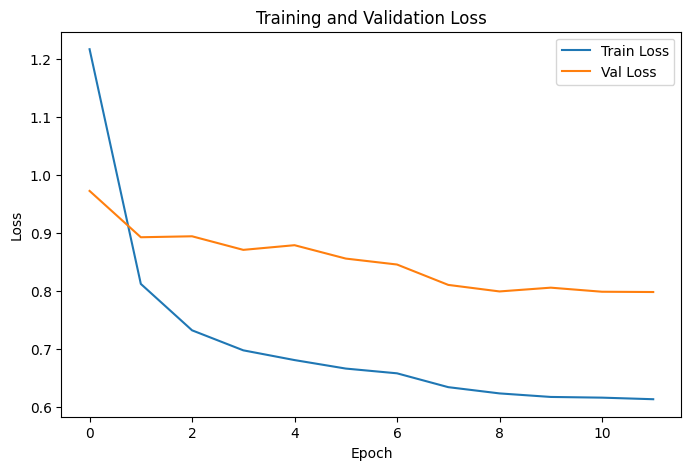

In [14]:
#loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

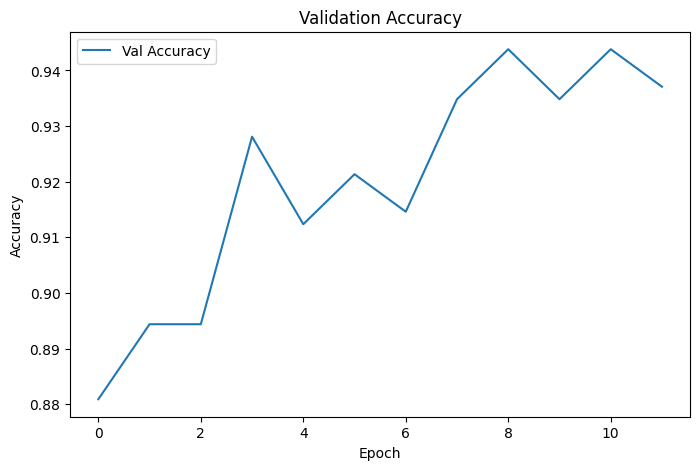

In [15]:
#acc
plt.figure(figsize=(8, 5))
plt.plot(val_accuracies, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.show()

### Testing


Test Accuracy: 92.63%

Test Classification Report:

              precision    recall  f1-score   support

       Adult       0.92      0.80      0.86        30
    Airplane       0.94      0.97      0.95        30
      Alpaca       0.97      1.00      0.98        30
        Bird       0.97      0.97      0.97        30
         Bus       0.88      1.00      0.94        30
         Car       1.00      0.97      0.98        30
         Cat       0.84      0.90      0.87        30
       Child       0.78      0.97      0.87        30
         Dog       0.77      0.80      0.79        30
    Elephant       0.97      0.97      0.97        30
      Flower       0.93      0.90      0.92        30
     Giraffe       0.97      0.93      0.95        30
       Horse       0.96      0.77      0.85        30
      Monkey       0.87      0.90      0.89        30
       Panda       0.96      0.90      0.93        30
     Reptile       1.00      0.97      0.98        30
       Train       0.96     

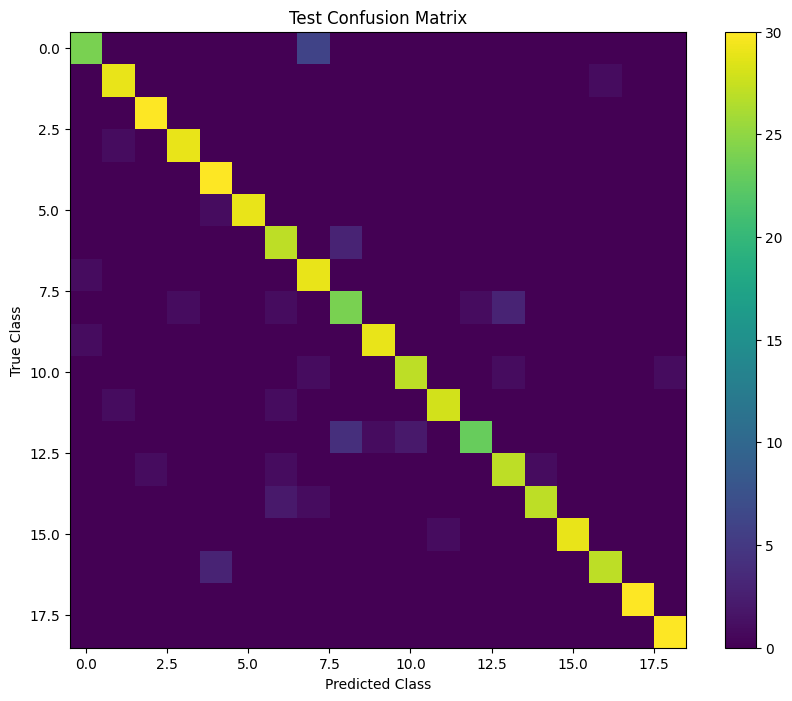

Saved best model to best_resnet18_model.pth


In [16]:
model.eval()

test_preds = []
test_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_targets, test_preds)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")

print("\nTest Classification Report:\n")
print(classification_report(test_targets, test_preds, target_names=class_names, zero_division=0))

cm = confusion_matrix(test_targets, test_preds)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest")
plt.title("Test Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

#chatgpt says i should save best model. i guess makes sense as it does take its time to train
torch.save(model.state_dict(), "best_resnet18_model.pth")
print("Saved best model to best_resnet18_model.pth")

### Notes

was running for so long and nothing happened i forgot to use CUDA stuff. added that

after debugged and ran for the first time i got 92% test accuracy!!! it did get above 90% quickly. im adding a feature that stops the training after the model doesnt improve after a certain amount of epochs. also reducing epochs to 12 i dont think i need 25